In [1]:
print("Colab is working!")

Colab is working!


In [2]:
!java -version

[0.020s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.020s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


In [3]:
!ls -lah /content

total 16K
drwxr-xr-x 1 root root 4.0K Oct 17 23:09 .
drwxr-xr-x 1 root root 4.0K Oct 22 15:20 ..
drwxr-xr-x 4 root root 4.0K Oct 17 23:09 .config
drwxr-xr-x 1 root root 4.0K Oct 17 23:09 sample_data


In [4]:
!wget -q https://downloads.apache.org/hadoop/common/ -O /tmp/hadoop_page.html
!head -c 500 /tmp/hadoop_page.html

<!DOCTYPE HTML PUBLIC "-//W3C//DTD HTML 3.2 Final//EN">
<html>
 <head>
  <title>Index of /hadoop/common</title>
 </head>
 <body>
<h1>Index of /hadoop/common</h1>
<pre><img src="/icons/blank.gif" alt="Icon "> <a href="?C=N;O=D">Name</a>                    <a href="?C=M;O=A">Last modified</a>      <a href="?C=S;O=A">Size</a>  <a href="?C=D;O=A">Description</a><hr><img src="/icons/back.gif" alt="[PARENTDIR]"> <a href="/hadoop/">Parent Directory</a>                             -   
<img src="/icons/

In [5]:
!pip install -q pyspark

In [6]:
import pyspark
print("PySpark version:", pyspark.__version__)

PySpark version: 4.0.4


In [7]:
!wget -q https://downloads.apache.org/hadoop/common/hadoop-3.4.2/hadoop-3.4.2.tar.gz -O /content/hadoop.tar.gz

!tar -xzf /content/hadoop.tar.gz -C /content/

!ls -ld /content/hadoop-3.4.2

drwxr-xr-x 10 1001 1001 4096 Aug 20  2025 /content/hadoop-3.4.2


In [8]:
import os

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-21-openjdk-amd64"
os.environ["HADOOP_HOME"] = "/content/hadoop-3.4.2"
os.environ["PATH"] += ":/content/hadoop-3.4.2/bin:/content/hadoop-3.4.2/sbin"

!hadoop version

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Hadoop 3.4.2
Source code repository https://github.com/apache/hadoop.git -r 84e8b89ee2ebe6923691205b9e171badde7a495c
Compiled by ahmarsu on 2025-08-20T10:30Z
Compiled on platform linux-x86_64
Compiled with protoc 3.23.4
From source with checksum fa94c67d4b4be021b9e9515c9b0f7b6
This command was run using /content/hadoop-3.4.2/share/hadoop/common/hadoop-common-3.4.2.jar


In [9]:
%%bash
set -e

H=/content/hadoop-3.4.2
CONF="$H/etc/hadoop"

cat > "$CONF/core-site.xml" <<'EOF'
<?xml version="1.0"?>
<configuration>
  <property>
    <name>fs.defaultFS</name>
    <value>hdfs://localhost:9000</value>
  </property>
</configuration>
EOF

cat > "$CONF/hdfs-site.xml" <<'EOF'
<?xml version="1.0"?>
<configuration>
  <property>
    <name>dfs.replication</name>
    <value>1</value>
  </property>
  <property>
    <name>dfs.namenode.name.dir</name>
    <value>file:///content/hadoop-data/namenode</value>
  </property>
  <property>
    <name>dfs.datanode.data.dir</name>
    <value>file:///content/hadoop-data/datanode</value>
  </property>
</configuration>
EOF

echo "HDFS configuration files created successfully."

HDFS configuration files created successfully.


In [10]:
!hdfs namenode -format

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
2026-10-22 15:27:44,265 INFO namenode.NameNode: STARTUP_MSG: 
/************************************************************
STARTUP_MSG: Starting NameNode
STARTUP_MSG:   host = d3e12ff88e9f/172.28.0.12
STARTUP_MSG:   args = [-format]
STARTUP_MSG:   version = 3.4.2
STARTUP_MSG:   classpath = /content/hadoop-3.4.2/etc/hadoop:/content/hadoop-3.4.2/share/hadoop/common/lib/jersey-json-1.22.0.jar:/content/hadoop-3.4.2/share/hadoop/common/lib/hadoop-shaded-protobuf_3_25-1.4.0.jar:/content/hadoop-3.4.2/share/hadoop/common/lib/netty-common-4.1.118.Final.jar:/content/hadoop-3.4.2/share/hadoop/common/lib/avro-1.11.4.jar:/content/hadoop-3.4.2/share/hadoop/common/lib/netty-tr

In [11]:
import os

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-21-openjdk-amd64"
os.environ["HADOOP_HOME"] = "/content/hadoop-3.4.2"
os.environ["HADOOP_CONF_DIR"] = "/content/hadoop-3.4.2/etc/hadoop"
os.environ["PATH"] += ":/content/hadoop-3.4.2/bin:/content/hadoop-3.4.2/sbin"

!hdfs --daemon start namenode
!hdfs --daemon start datanode

In [12]:
!hdfs dfsadmin -report

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Configured Capacity: 115658190848 (107.72 GB)
Present Capacity: 90638909440 (84.41 GB)
DFS Remaining: 90638884864 (84.41 GB)
DFS Used: 24576 (24 KB)
DFS Used%: 0.00%
Replicated Blocks:
	Under replicated blocks: 0
	Blocks with corrupt replicas: 0
	Missing blocks: 0
	Missing blocks (with replication factor 1): 0
	Low redundancy blocks with highest priority to recover: 0
	Pending deletion blocks: 0
Erasure Coded Block Groups: 
	Low redundancy block groups: 0
	Block groups with corrupt internal blocks: 0
	Missing block groups: 0
	Low redundancy blocks with highest priority to recover: 0
	Pending deletion blocks: 0

-------------------------------------------------
Li

In [13]:
!hdfs dfs -mkdir -p /food_delivery
!hdfs dfs -ls /

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Found 1 items
drwxr-xr-x   - root supergroup          0 2026-10-22 15:29 /food_delivery


In [15]:
from google.colab import files

uploaded = files.upload()

Saving Sample_Submission.csv to Sample_Submission (1).csv


In [16]:
!ls -lh /content/*.csv

-rw-r--r-- 1 root root 268K Oct 22 15:33 '/content/Sample_Submission (1).csv'
-rw-r--r-- 1 root root 268K Oct 22 15:33  /content/Sample_Submission.csv


In [18]:
!hdfs dfs -put -f /content/Sample_Submission.csv /food_delivery/
!hdfs dfs -ls /food_delivery/

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Found 1 items
-rw-r--r--   1 root supergroup     273471 2026-10-22 15:34 /food_delivery/Sample_Submission.csv


In [19]:
!ls -lh /content/

total 1017M
drwxr-xr-x 11 1001 1001  4.0K Oct 22 15:27  hadoop-3.4.2
drwxr-xr-x  4 root root  4.0K Oct 22 15:28  hadoop-data
-rw-r--r--  1 root root 1017M Oct  4  2025  hadoop.tar.gz
drwxr-xr-x  1 root root  4.0K Oct 17 23:09  sample_data
-rw-r--r--  1 root root  268K Oct 22 15:33 'Sample_Submission (1).csv'
-rw-r--r--  1 root root  268K Oct 22 15:33  Sample_Submission.csv


In [20]:
from google.colab import files
uploaded = files.upload()

Saving train.csv to train.csv


In [21]:
!ls -lh /content/train.csv

-rw-r--r-- 1 root root 7.5M Oct 22 15:37 /content/train.csv


In [22]:
!hdfs dfs -mkdir -p /food_delivery
!hdfs dfs -put -f /content/train.csv /food_delivery/
!hdfs dfs -ls /food_delivery/

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Found 2 items

In [23]:
!hdfs dfs -cat /food_delivery/train.csv | head -n 5

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0x4607 ,INDORES13DEL02 ,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High ,2,Snack ,motorcycle ,0,No ,Urban ,(min) 24
0xb379 ,BANGRES18DEL02 ,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam ,2,Snack ,scooter ,1,No ,Metropolitian ,(mi

In [24]:
from pyspark.sql import SparkSession
spark = SparkSession.builder \
    .appName("FoodDeliveryAnalysis") \
    .master("local[*]") \
    .getOrCreate()
df = spark.read \
    .option("header", True) \
    .option("inferSchema", True) \
    .csv("hdfs://localhost:9000/food_delivery/train.csv")
print("Total rows:", df.count())
print("Total columns:", len(df.columns))
df.printSchema()
df.show(5, truncate=False)

Total rows: 45593
Total columns: 20
root
 |-- ID: string (nullable = true)
 |-- Delivery_person_ID: string (nullable = true)
 |-- Delivery_person_Age: double (nullable = true)
 |-- Delivery_person_Ratings: double (nullable = true)
 |-- Restaurant_latitude: double (nullable = true)
 |-- Restaurant_longitude: double (nullable = true)
 |-- Delivery_location_latitude: double (nullable = true)
 |-- Delivery_location_longitude: double (nullable = true)
 |-- Order_Date: string (nullable = true)
 |-- Time_Orderd: string (nullable = true)
 |-- Time_Order_picked: timestamp (nullable = true)
 |-- Weatherconditions: string (nullable = true)
 |-- Road_traffic_density: string (nullable = true)
 |-- Vehicle_condition: integer (nullable = true)
 |-- Type_of_order: string (nullable = true)
 |-- Type_of_vehicle: string (nullable = true)
 |-- multiple_deliveries: double (nullable = true)
 |-- Festival: string (nullable = true)
 |-- City: string (nullable = true)
 |-- Time_taken(min): string (nullable = t

In [25]:
from pyspark.sql import functions as F
# Convert delivery time to numeric minutes
df_clean = df.withColumn(
    "Delivery_Time",
    F.regexp_extract(F.col("`Time_taken(min)`"), r"(\d+)", 1).cast("double")
)
# Clean weather values
df_clean = df_clean.withColumn(
    "Weatherconditions",
    F.regexp_replace(F.col("Weatherconditions"), r"^conditions\s*", "")
)
# Convert invalid or blank strings to null for selected columns
for c in ["Weatherconditions", "Road_traffic_density", "City", "Festival"]:
    df_clean = df_clean.withColumn(
        c,
        F.when(
            F.trim(F.col(c)).isin("", "NaN", "null", "NULL"),
            None
        ).otherwise(F.trim(F.col(c)))
    )
print("Rows:", df_clean.count())
print("Columns:", len(df_clean.columns))
df_clean.select(
    "Weatherconditions",
    "Road_traffic_density",
    "Type_of_vehicle",
    "City",
    "Delivery_Time"
).show(10, truncate=False)

Rows: 45593
Columns: 21
+-----------------+--------------------+---------------+-------------+-------------+
|Weatherconditions|Road_traffic_density|Type_of_vehicle|City         |Delivery_Time|
+-----------------+--------------------+---------------+-------------+-------------+
|Sunny            |High                |motorcycle     |Urban        |24.0         |
|Stormy           |Jam                 |scooter        |Metropolitian|33.0         |
|Sandstorms       |Low                 |motorcycle     |Urban        |26.0         |
|Sunny            |Medium              |motorcycle     |Metropolitian|21.0         |
|Cloudy           |High                |scooter        |Metropolitian|30.0         |
|Cloudy           |Jam                 |motorcycle     |Urban        |26.0         |
|Fog              |Jam                 |scooter        |Metropolitian|40.0         |
|Cloudy           |Medium              |motorcycle     |Metropolitian|32.0         |
|Stormy           |Jam                 |m

In [26]:
from pyspark.sql import functions as F
missing_exprs = [
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in df_clean.columns
]
df_clean.select(*missing_exprs).show(truncate=False)

+---+------------------+-------------------+-----------------------+-------------------+--------------------+--------------------------+---------------------------+----------+-----------+-----------------+-----------------+--------------------+-----------------+-------------+---------------+-------------------+--------+----+---------------+-------------+
|ID |Delivery_person_ID|Delivery_person_Age|Delivery_person_Ratings|Restaurant_latitude|Restaurant_longitude|Delivery_location_latitude|Delivery_location_longitude|Order_Date|Time_Orderd|Time_Order_picked|Weatherconditions|Road_traffic_density|Vehicle_condition|Type_of_order|Type_of_vehicle|multiple_deliveries|Festival|City|Time_taken(min)|Delivery_Time|
+---+------------------+-------------------+-----------------------+-------------------+--------------------+--------------------------+---------------------------+----------+-----------+-----------------+-----------------+--------------------+-----------------+-------------+----------

In [27]:
traffic_analysis = (
    df_clean
    .filter(F.col("Delivery_Time").isNotNull())
    .groupBy("Road_traffic_density")
    .agg(
        F.count("*").alias("Total_Orders"),
        F.round(F.avg("Delivery_Time"), 2).alias("Avg_Delivery_Minutes")
    )
    .orderBy(F.desc("Avg_Delivery_Minutes"))
)

traffic_analysis.show(truncate=False)

+--------------------+------------+--------------------+
|Road_traffic_density|Total_Orders|Avg_Delivery_Minutes|
+--------------------+------------+--------------------+
|Jam                 |14143       |31.18               |
|High                |4425        |27.24               |
|Medium              |10947       |26.7                |
|NULL                |601         |26.54               |
|Low                 |15477       |21.27               |
+--------------------+------------+--------------------+



In [28]:
vehicle_analysis = (
    df_clean
    .filter(F.col("Delivery_Time").isNotNull())
    .groupBy("Type_of_vehicle")
    .agg(
        F.count("*").alias("Total_Orders"),
        F.round(F.avg("Delivery_Time"), 2).alias("Avg_Delivery_Minutes")
    )
    .orderBy(F.desc("Avg_Delivery_Minutes"))
)

vehicle_analysis.show(truncate=False)

+-----------------+------------+--------------------+
|Type_of_vehicle  |Total_Orders|Avg_Delivery_Minutes|
+-----------------+------------+--------------------+
|motorcycle       |26435       |27.61               |
|bicycle          |68          |26.43               |
|scooter          |15276       |24.48               |
|electric_scooter |3814        |24.47               |
+-----------------+------------+--------------------+



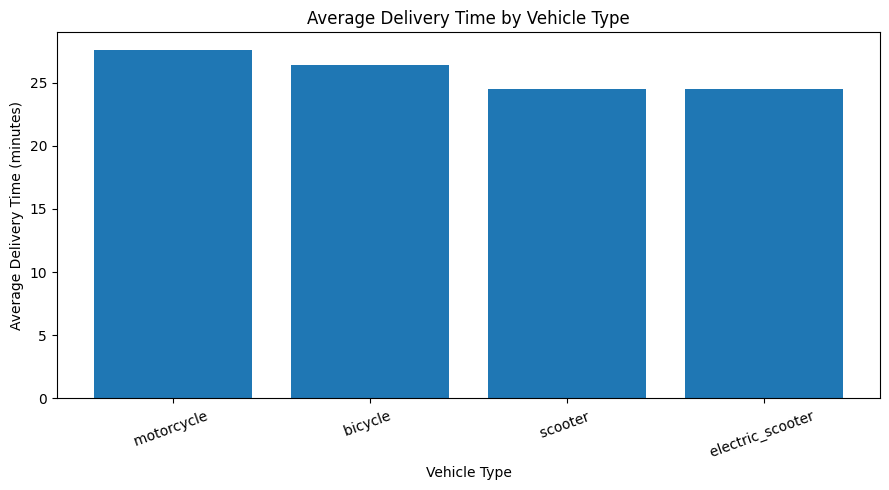

In [29]:
import matplotlib.pyplot as plt

vehicle_pd = vehicle_analysis.toPandas()

plt.figure(figsize=(9, 5))
plt.bar(
    vehicle_pd["Type_of_vehicle"],
    vehicle_pd["Avg_Delivery_Minutes"]
)
plt.title("Average Delivery Time by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Average Delivery Time (minutes)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [30]:
from pyspark.sql import functions as F
traffic_analysis = (
    df_clean
    .filter(F.col("Delivery_Time").isNotNull())
    .groupBy("Road_traffic_density")
    .agg(
        F.count("*").alias("Total_Orders"),
        F.round(F.avg("Delivery_Time"), 2)
         .alias("Avg_Delivery_Minutes")
    )
)
traffic_analysis.show(truncate=False)

+--------------------+------------+--------------------+
|Road_traffic_density|Total_Orders|Avg_Delivery_Minutes|
+--------------------+------------+--------------------+
|High                |4425        |27.24               |
|Low                 |15477       |21.27               |
|NULL                |601         |26.54               |
|Medium              |10947       |26.7                |
|Jam                 |14143       |31.18               |
+--------------------+------------+--------------------+



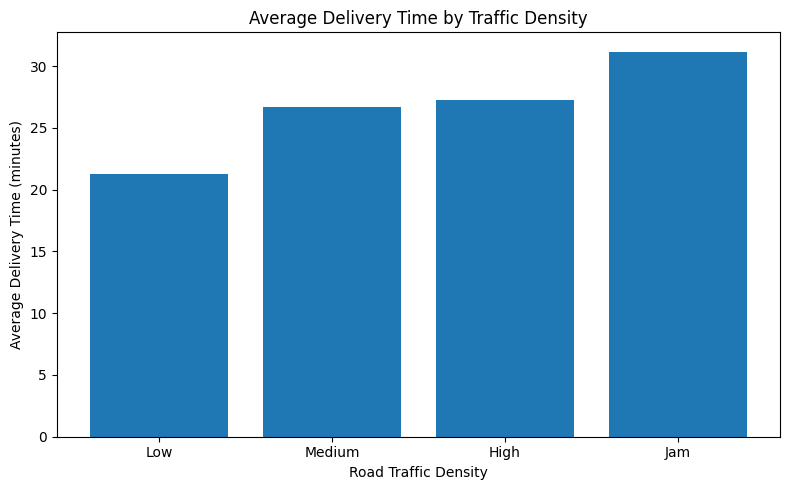

In [33]:
import matplotlib.pyplot as plt
traffic_pd = traffic_analysis.toPandas()
# Remove missing traffic categories
traffic_pd = traffic_pd.dropna(
    subset=["Road_traffic_density", "Avg_Delivery_Minutes"]
)
# Arrange traffic levels logically
traffic_order = ["Low", "Medium", "High", "Jam"]

traffic_pd["sort_order"] = traffic_pd["Road_traffic_density"].apply(
    lambda x: traffic_order.index(x)
    if x in traffic_order else len(traffic_order)
)
traffic_pd = traffic_pd.sort_values("sort_order")
# Create graph
plt.figure(figsize=(8, 5))
plt.bar(
    traffic_pd["Road_traffic_density"].astype(str),
    traffic_pd["Avg_Delivery_Minutes"]
)
plt.title("Average Delivery Time by Traffic Density")
plt.xlabel("Road Traffic Density")
plt.ylabel("Average Delivery Time (minutes)")
plt.tight_layout()
plt.show()

In [34]:
from pyspark.sql import functions as F

weather_analysis = (
    df_clean
    .filter(
        F.col("Delivery_Time").isNotNull() &
        F.col("Weatherconditions").isNotNull()
    )
    .groupBy("Weatherconditions")
    .agg(
        F.count("*").alias("Total_Orders"),
        F.round(F.avg("Delivery_Time"), 2)
         .alias("Avg_Delivery_Minutes")
    )
    .orderBy(F.desc("Avg_Delivery_Minutes"))
)

weather_analysis.show(truncate=False)

+-----------------+------------+--------------------+
|Weatherconditions|Total_Orders|Avg_Delivery_Minutes|
+-----------------+------------+--------------------+
|Cloudy           |7536        |28.92               |
|Fog              |7654        |28.92               |
|Windy            |7422        |26.12               |
|Sandstorms       |7495        |25.88               |
|Stormy           |7586        |25.87               |
|Sunny            |7284        |21.86               |
+-----------------+------------+--------------------+



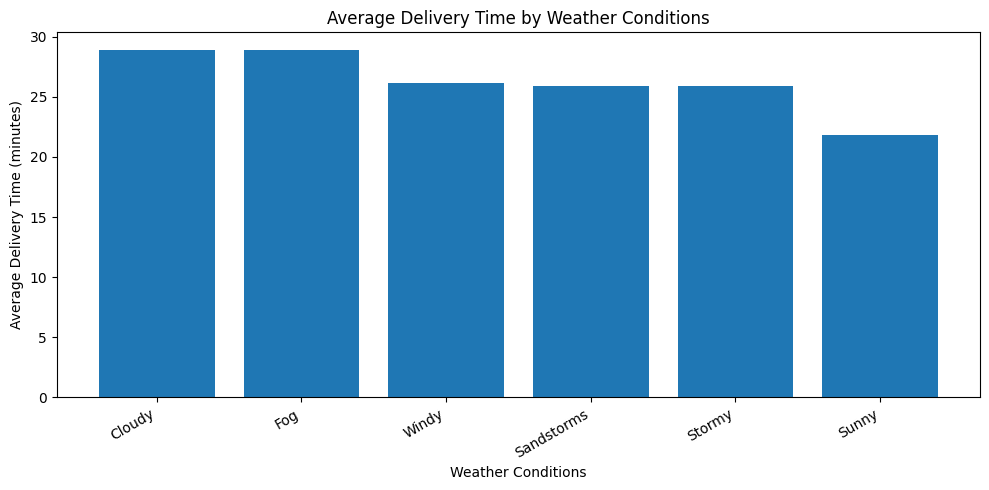

In [35]:
import matplotlib.pyplot as plt
weather_pd = weather_analysis.toPandas()
# Remove missing values
weather_pd = weather_pd.dropna(
    subset=["Weatherconditions", "Avg_Delivery_Minutes"]
)
plt.figure(figsize=(10, 5))
plt.bar(
    weather_pd["Weatherconditions"].astype(str),
    weather_pd["Avg_Delivery_Minutes"]
)
plt.title("Average Delivery Time by Weather Conditions")
plt.xlabel("Weather Conditions")
plt.ylabel("Average Delivery Time (minutes)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [36]:
from pyspark.sql import functions as F

rating_analysis = (
    df_clean
    .filter(
        F.col("Delivery_person_Ratings").isNotNull() &
        F.col("Delivery_Time").isNotNull()
    )
    .groupBy("Delivery_person_Ratings")
    .agg(
        F.count("*").alias("Total_Orders"),
        F.round(F.avg("Delivery_Time"), 2)
         .alias("Avg_Delivery_Minutes")
    )
    .orderBy("Delivery_person_Ratings")
)

rating_analysis.show(truncate=False)

+-----------------------+------------+--------------------+
|Delivery_person_Ratings|Total_Orders|Avg_Delivery_Minutes|
+-----------------------+------------+--------------------+
|1.0                    |38          |26.0                |
|2.5                    |20          |37.3                |
|2.6                    |22          |38.59               |
|2.7                    |22          |35.86               |
|2.8                    |19          |36.63               |
|2.9                    |19          |38.53               |
|3.0                    |6           |32.67               |
|3.1                    |29          |36.55               |
|3.2                    |29          |36.34               |
|3.3                    |25          |36.04               |
|3.4                    |32          |35.72               |
|3.5                    |249         |37.06               |
|3.6                    |207         |37.29               |
|3.7                    |225         |37

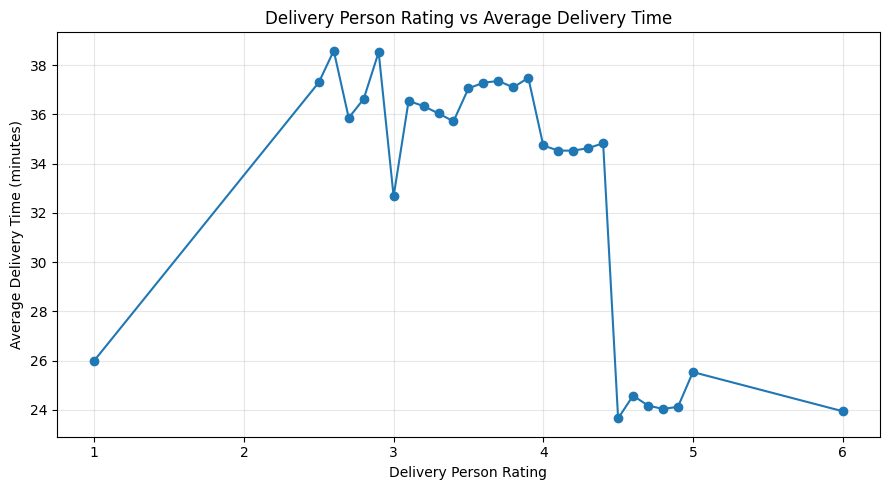

In [37]:
import matplotlib.pyplot as plt
rating_pd = rating_analysis.toPandas()
rating_pd = rating_pd.dropna(
    subset=["Delivery_person_Ratings", "Avg_Delivery_Minutes"]
)
plt.figure(figsize=(9, 5))
plt.plot(
    rating_pd["Delivery_person_Ratings"],
    rating_pd["Avg_Delivery_Minutes"],
    marker="o"
)
plt.title("Delivery Person Rating vs Average Delivery Time")
plt.xlabel("Delivery Person Rating")
plt.ylabel("Average Delivery Time (minutes)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [38]:
from pyspark.sql import functions as F

order_analysis = (
    df_clean
    .filter(
        F.col("Type_of_order").isNotNull() &
        F.col("Delivery_Time").isNotNull()
    )
    .groupBy("Type_of_order")
    .agg(
        F.count("*").alias("Total_Orders"),
        F.round(F.avg("Delivery_Time"), 2)
         .alias("Avg_Delivery_Minutes")
    )
    .orderBy(F.desc("Avg_Delivery_Minutes"))
)

order_analysis.show(truncate=False)

+-------------+------------+--------------------+
|Type_of_order|Total_Orders|Avg_Delivery_Minutes|
+-------------+------------+--------------------+
|Meal         |11458       |26.42               |
|Snack        |11533       |26.29               |
|Buffet       |11280       |26.28               |
|Drinks       |11322       |26.19               |
+-------------+------------+--------------------+



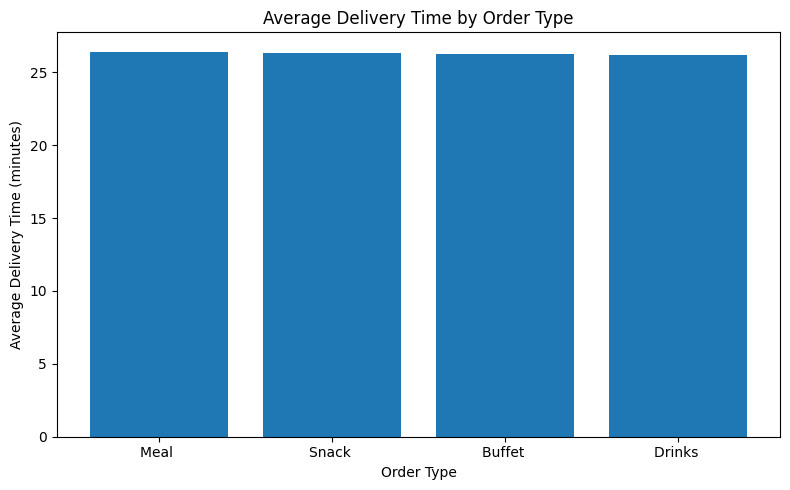

In [39]:
import matplotlib.pyplot as plt

order_pd = order_analysis.toPandas()

order_pd = order_pd.dropna(
    subset=["Type_of_order", "Avg_Delivery_Minutes"]
)

plt.figure(figsize=(8, 5))
plt.bar(
    order_pd["Type_of_order"].astype(str),
    order_pd["Avg_Delivery_Minutes"]
)

plt.title("Average Delivery Time by Order Type")
plt.xlabel("Order Type")
plt.ylabel("Average Delivery Time (minutes)")
plt.tight_layout()
plt.show()

In [40]:
from pyspark.sql import functions as F

city_analysis = (
    df_clean
    .filter(
        F.col("City").isNotNull() &
        F.col("Delivery_Time").isNotNull()
    )
    .groupBy("City")
    .agg(
        F.count("*").alias("Total_Orders"),
        F.round(F.avg("Delivery_Time"), 2)
         .alias("Avg_Delivery_Minutes")
    )
    .orderBy(F.desc("Avg_Delivery_Minutes"))
)

city_analysis.show(truncate=False)

+-------------+------------+--------------------+
|City         |Total_Orders|Avg_Delivery_Minutes|
+-------------+------------+--------------------+
|Semi-Urban   |164         |49.73               |
|Metropolitian|34093       |27.32               |
|Urban        |10136       |22.98               |
+-------------+------------+--------------------+



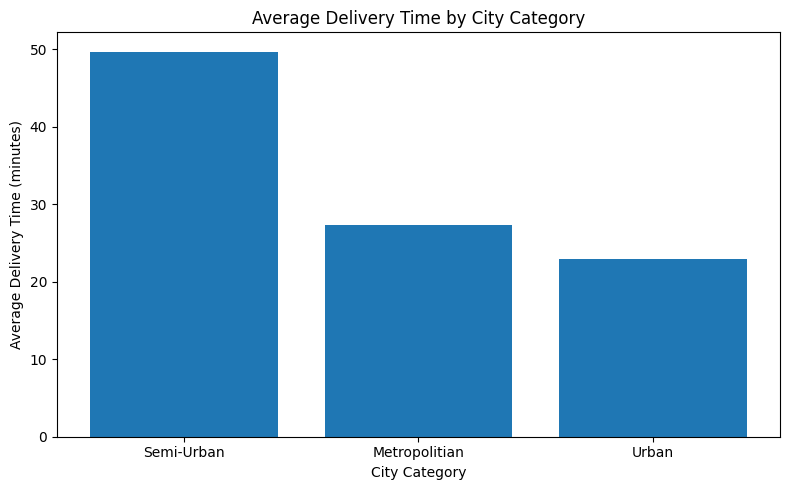

In [41]:
import matplotlib.pyplot as plt

city_pd = city_analysis.toPandas()

city_pd = city_pd.dropna(
    subset=["City", "Avg_Delivery_Minutes"]
)

plt.figure(figsize=(8, 5))
plt.bar(
    city_pd["City"].astype(str),
    city_pd["Avg_Delivery_Minutes"]
)

plt.title("Average Delivery Time by City Category")
plt.xlabel("City Category")
plt.ylabel("Average Delivery Time (minutes)")
plt.tight_layout()
plt.show()

In [42]:
from pyspark.sql import functions as F

festival_analysis = (
    df_clean
    .filter(
        F.col("Festival").isNotNull() &
        F.col("Delivery_Time").isNotNull()
    )
    .groupBy("Festival")
    .agg(
        F.count("*").alias("Total_Orders"),
        F.round(F.avg("Delivery_Time"), 2)
         .alias("Avg_Delivery_Minutes")
    )
    .orderBy(F.desc("Avg_Delivery_Minutes"))
)

festival_analysis.show(truncate=False)

+--------+------------+--------------------+
|Festival|Total_Orders|Avg_Delivery_Minutes|
+--------+------------+--------------------+
|Yes     |896         |45.52               |
|No      |44469       |25.98               |
+--------+------------+--------------------+



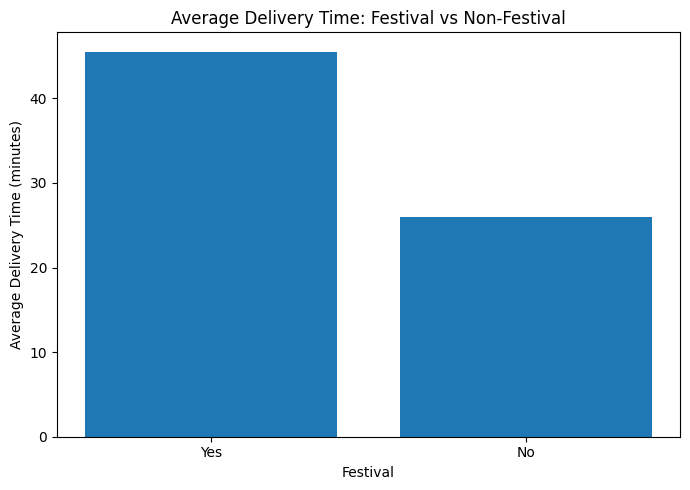

In [43]:
import matplotlib.pyplot as plt

festival_pd = festival_analysis.toPandas()

plt.figure(figsize=(7, 5))
plt.bar(
    festival_pd["Festival"].astype(str),
    festival_pd["Avg_Delivery_Minutes"]
)

plt.title("Average Delivery Time: Festival vs Non-Festival")
plt.xlabel("Festival")
plt.ylabel("Average Delivery Time (minutes)")
plt.tight_layout()
plt.show()

In [44]:
multiple_delivery_analysis = (
    df_clean
    .filter(
        F.col("multiple_deliveries").isNotNull() &
        F.col("Delivery_Time").isNotNull()
    )
    .groupBy("multiple_deliveries")
    .agg(
        F.count("*").alias("Total_Orders"),
        F.round(F.avg("Delivery_Time"), 2)
         .alias("Avg_Delivery_Minutes")
    )
    .orderBy("multiple_deliveries")
)

multiple_delivery_analysis.show(truncate=False)

+-------------------+------------+--------------------+
|multiple_deliveries|Total_Orders|Avg_Delivery_Minutes|
+-------------------+------------+--------------------+
|0.0                |14095       |22.88               |
|1.0                |28159       |26.86               |
|2.0                |1985        |40.45               |
|3.0                |361         |47.82               |
|NaN                |993         |22.77               |
+-------------------+------------+--------------------+



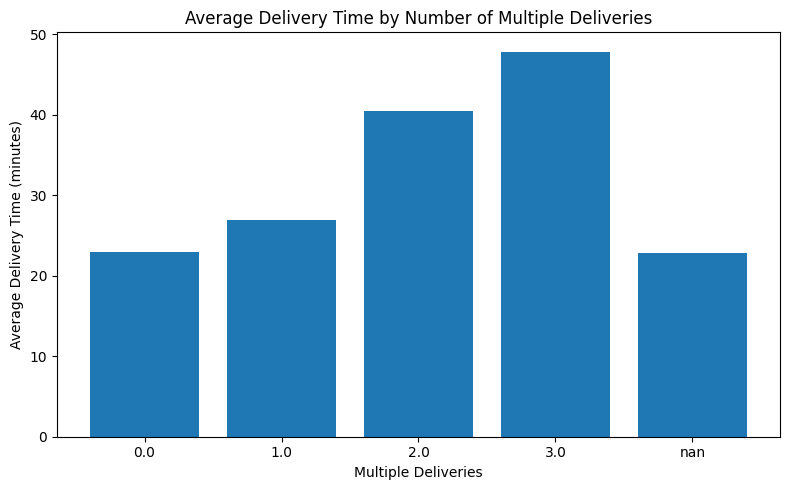

In [45]:
multiple_pd = multiple_delivery_analysis.toPandas()

plt.figure(figsize=(8, 5))
plt.bar(
    multiple_pd["multiple_deliveries"].astype(str),
    multiple_pd["Avg_Delivery_Minutes"]
)

plt.title("Average Delivery Time by Number of Multiple Deliveries")
plt.xlabel("Multiple Deliveries")
plt.ylabel("Average Delivery Time (minutes)")
plt.tight_layout()
plt.show()

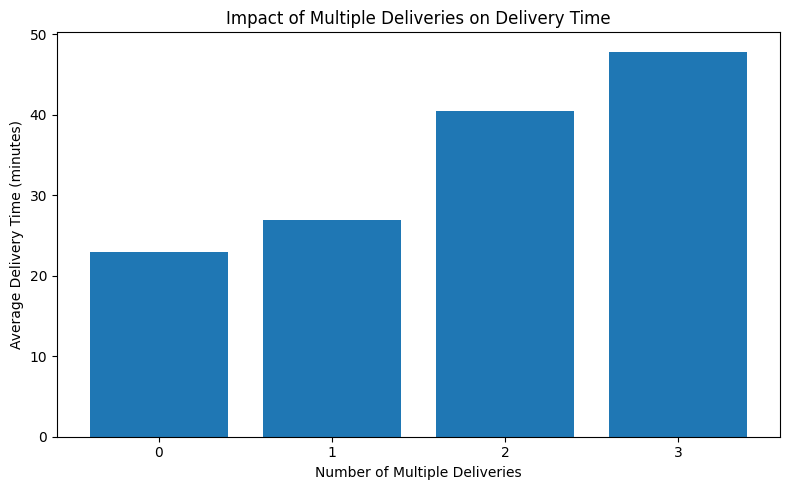

In [47]:
multiple_pd = multiple_delivery_analysis.toPandas()
multiple_pd = multiple_pd.dropna(
    subset=["multiple_deliveries", "Avg_Delivery_Minutes"]
)
multiple_pd = multiple_pd[
    multiple_pd["multiple_deliveries"].isin([0.0, 1.0, 2.0, 3.0])
]
multiple_pd = multiple_pd.sort_values("multiple_deliveries")
plt.figure(figsize=(8, 5))
plt.bar(
    multiple_pd["multiple_deliveries"].astype(int).astype(str),
    multiple_pd["Avg_Delivery_Minutes"]
)
plt.title("Impact of Multiple Deliveries on Delivery Time")
plt.xlabel("Number of Multiple Deliveries")
plt.ylabel("Average Delivery Time (minutes)")

plt.tight_layout()
plt.show()

In [48]:
import os

output_dir = "/content/food_delivery_results"
os.makedirs(output_dir, exist_ok=True)

analyses = {
    "vehicle_analysis": vehicle_analysis,
    "traffic_analysis": traffic_analysis,
    "weather_analysis": weather_analysis,
    "rating_analysis": rating_analysis,
    "order_analysis": order_analysis,
    "city_analysis": city_analysis,
    "festival_analysis": festival_analysis,
    "multiple_delivery_analysis": multiple_delivery_analysis
}

for name, analysis_df in analyses.items():
    analysis_df.toPandas().to_csv(
        f"{output_dir}/{name}.csv",
        index=False
    )

print("All analysis CSV files exported successfully!")
print(os.listdir(output_dir))

All analysis CSV files exported successfully!
['weather_analysis.csv', 'festival_analysis.csv', 'city_analysis.csv', 'vehicle_analysis.csv', 'multiple_delivery_analysis.csv', 'traffic_analysis.csv', 'rating_analysis.csv', 'order_analysis.csv']


In [49]:
summary = df_clean.agg(
    F.count("*").alias("Total_Orders"),
    F.round(F.avg("Delivery_Time"), 2).alias("Avg_Delivery_Minutes"),
    F.round(F.min("Delivery_Time"), 2).alias("Min_Delivery_Minutes"),
    F.round(F.max("Delivery_Time"), 2).alias("Max_Delivery_Minutes")
)

summary.show()

summary.toPandas().to_csv(
    "/content/food_delivery_results/overall_summary.csv",
    index=False
)

+------------+--------------------+--------------------+--------------------+
|Total_Orders|Avg_Delivery_Minutes|Min_Delivery_Minutes|Max_Delivery_Minutes|
+------------+--------------------+--------------------+--------------------+
|       45593|               26.29|                10.0|                54.0|
+------------+--------------------+--------------------+--------------------+



In [50]:
import shutil

zip_path = shutil.make_archive(
    "/content/food_delivery_results",
    "zip",
    output_dir
)

print("ZIP created:", zip_path)

ZIP created: /content/food_delivery_results.zip


In [51]:
import os

for file in sorted(os.listdir("/content/food_delivery_results")):
    print(file)

city_analysis.csv
festival_analysis.csv
multiple_delivery_analysis.csv
order_analysis.csv
overall_summary.csv
rating_analysis.csv
traffic_analysis.csv
vehicle_analysis.csv
weather_analysis.csv


In [52]:
from google.colab import files

files.download("/content/food_delivery_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>